# Digit Recognizer — starter notebook

Goal: recognise handwritten digits (0–9) from 28×28 grayscale images (MNIST).
Kaggle scores submissions by **accuracy** — the fraction of test images labelled correctly.

Plan:
1. Load the data and look at it.
2. Hold out part of `train.csv` as a validation set.
3. Baseline model: **nearest centroid** — one "average image" per digit; a new image gets the label of the closest average.
4. Evaluate on validation: accuracy, per-digit accuracy, confusion matrix, misclassified examples.
5. Write `submission.csv` for Kaggle.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

KAGGLE_DIR = Path("/kaggle/input/digit-recognizer")  # exists when run as a Kaggle notebook
LOCAL_DIR = Path("data")                              # train.csv / test.csv downloaded by hand or via the Kaggle API
SEED = 42

## 1. Load the data

Works in three places, picked automatically:
- **Kaggle notebook** — the competition files in `/kaggle/input/digit-recognizer`.
- **Kaggle files in `./data`** — `train.csv` and `test.csv` (see the optional cell below).
- **Anywhere else (e.g. Colab)** — the same MNIST digits from OpenML, no login needed. Good for learning;
  for a Kaggle submission you need Kaggle's `test.csv`.

Kaggle format: `train.csv` = column `label` + 784 pixel columns (0–255); `test.csv` = pixels only.

In [2]:
# Optional: get the original Kaggle files into ./data (Colab or your laptop).
# 1. kaggle.com → your profile → Settings → API → "Create New Token" downloads kaggle.json.
# 2. Accept the rules on https://www.kaggle.com/competitions/digit-recognizer (button "Join Competition").
# 3. Uncomment and run:
# from google.colab import files; files.upload()          # Colab only: pick kaggle.json
# !mkdir -p ~/.kaggle && mv kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
# !pip install -q kaggle
# !kaggle competitions download -c digit-recognizer -p data && unzip -o -q data/digit-recognizer.zip -d data

In [3]:
def read_kaggle_csv(folder: Path) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    train = pd.read_csv(folder / "train.csv")
    y = train.pop("label").to_numpy()
    X = train.to_numpy(dtype=np.float32) / 255.0
    X_test = pd.read_csv(folder / "test.csv").to_numpy(dtype=np.float32) / 255.0
    return X, y, X_test


def read_openml() -> tuple[np.ndarray, np.ndarray, None]:
    from sklearn.datasets import fetch_openml
    X, y = fetch_openml("mnist_784", version=1, as_frame=False, return_X_y=True, parser="liac-arff")
    return X[:42000].astype(np.float32) / 255.0, y[:42000].astype(int), None  # same size as Kaggle's train.csv


def load_data():
    for folder in (KAGGLE_DIR, LOCAL_DIR):
        if (folder / "train.csv").exists():
            print("data: Kaggle files in", folder)
            return read_kaggle_csv(folder)
    print("data: MNIST from OpenML (no Kaggle test.csv, so no submission file)")
    return read_openml()


X_all, y_all, X_test = load_data()
print("train:", X_all.shape, "labels:", y_all.shape)

data: MNIST from OpenML (no Kaggle test.csv, so no submission file)


train: (42000, 784) labels: (42000,)


## 2. Look at the data

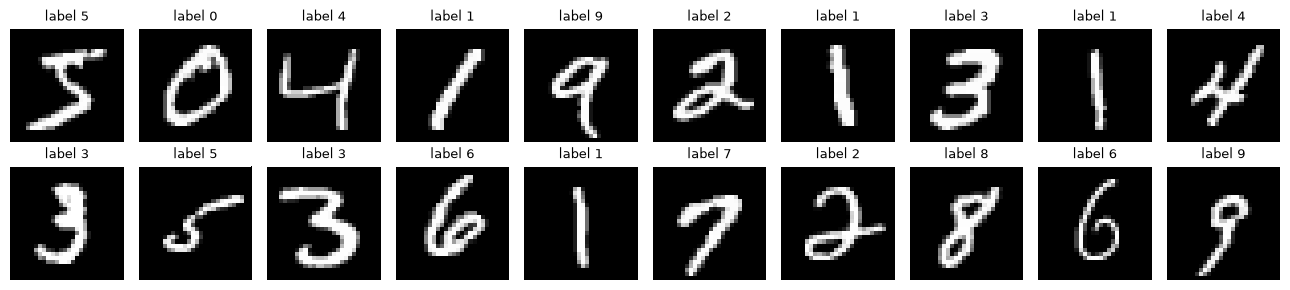

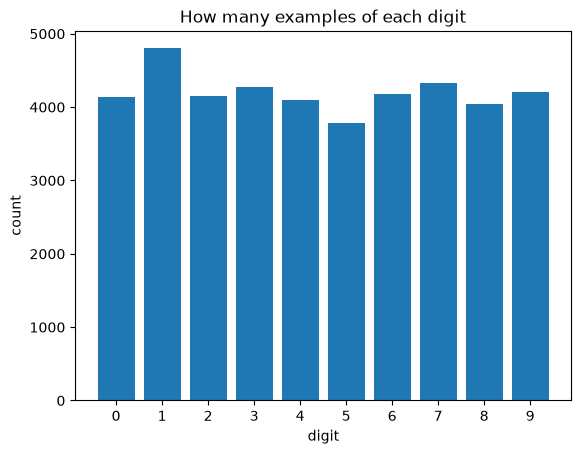

In [4]:
def show_images(X: np.ndarray, titles: list[str], cols: int = 10) -> None:
    rows = int(np.ceil(len(X) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 1.3, rows * 1.5))
    for ax in np.ravel(axes):
        ax.axis("off")
    for ax, img, title in zip(np.ravel(axes), X, titles):
        ax.imshow(img.reshape(28, 28), cmap="gray")
        ax.set_title(title, fontsize=9)
    plt.tight_layout()
    plt.show()


def show_label_counts(y: np.ndarray) -> None:
    digits, counts = np.unique(y, return_counts=True)
    plt.bar(digits, counts)
    plt.xticks(digits)
    plt.xlabel("digit")
    plt.ylabel("count")
    plt.title("How many examples of each digit")
    plt.show()


show_images(X_all[:20], [f"label {d}" for d in y_all[:20]])
show_label_counts(y_all)

## 3. Train / validation split
We never tune on the validation part — it stands in for Kaggle's hidden test set.

In [5]:
def split(X: np.ndarray, y: np.ndarray, val_fraction: float = 0.2, seed: int = SEED):
    idx = np.random.default_rng(seed).permutation(len(X))
    n_val = int(len(X) * val_fraction)
    val, train = idx[:n_val], idx[n_val:]
    return X[train], y[train], X[val], y[val]


X_train, y_train, X_val, y_val = split(X_all, y_all)
print("train:", len(X_train), "validation:", len(X_val))

train: 33600 validation: 8400


## 4. Baseline: nearest centroid
No learning beyond averaging: the centroid of a digit is the mean of all its training images.

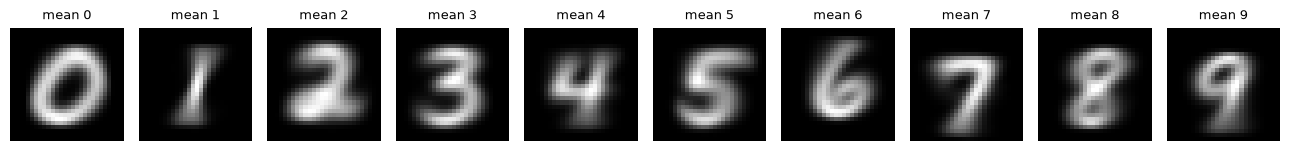

In [6]:
def fit_centroids(X: np.ndarray, y: np.ndarray) -> np.ndarray:
    return np.stack([X[y == d].mean(axis=0) for d in range(10)])  # (10, 784)


def predict(centroids: np.ndarray, X: np.ndarray) -> np.ndarray:
    distances = ((X[:, None, :] - centroids[None, :, :]) ** 2).sum(axis=2)  # (n, 10)
    return distances.argmin(axis=1)


centroids = fit_centroids(X_train, y_train)
show_images(centroids, [f"mean {d}" for d in range(10)])

## 5. Evaluation loop
Predict the validation set batch by batch, then compute the statistics.

In [7]:
def evaluate(predict_fn, X: np.ndarray, y: np.ndarray, batch_size: int = 1000) -> np.ndarray:
    preds = []
    for start in range(0, len(X), batch_size):
        batch = X[start:start + batch_size]
        preds.append(predict_fn(batch))
        print(f"\rpredicted {start + len(batch)}/{len(X)}", end="")
    print()
    return np.concatenate(preds)


def confusion_matrix(y_true: np.ndarray, y_pred: np.ndarray) -> np.ndarray:
    cm = np.zeros((10, 10), dtype=int)
    np.add.at(cm, (y_true, y_pred), 1)
    return cm  # rows = true digit, columns = predicted digit


def print_stats(y_true: np.ndarray, y_pred: np.ndarray) -> None:
    print(f"validation accuracy: {(y_true == y_pred).mean():.4f}")
    cm = confusion_matrix(y_true, y_pred)
    per_digit = cm.diagonal() / cm.sum(axis=1)
    for d in np.argsort(per_digit):
        print(f"  digit {d}: {per_digit[d]:.3f}")


y_pred = evaluate(lambda batch: predict(centroids, batch), X_val, y_val)
print_stats(y_val, y_pred)

predicted 8400/8400
validation accuracy: 0.8049
  digit 5: 0.655
  digit 8: 0.717
  digit 2: 0.760
  digit 3: 0.763
  digit 9: 0.770
  digit 4: 0.817
  digit 7: 0.847
  digit 6: 0.850
  digit 0: 0.872
  digit 1: 0.967


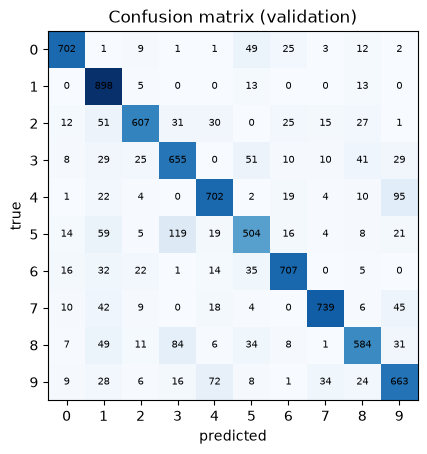

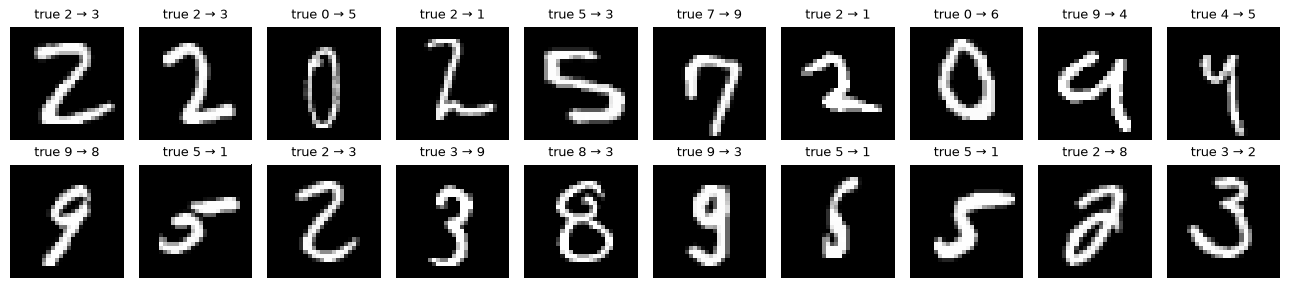

In [8]:
def show_confusion(cm: np.ndarray) -> None:
    plt.imshow(cm, cmap="Blues")
    for i in range(10):
        for j in range(10):
            plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=7)
    plt.xticks(range(10))
    plt.yticks(range(10))
    plt.xlabel("predicted")
    plt.ylabel("true")
    plt.title("Confusion matrix (validation)")
    plt.show()


def show_mistakes(X: np.ndarray, y_true: np.ndarray, y_pred: np.ndarray, n: int = 20) -> None:
    wrong = np.flatnonzero(y_true != y_pred)[:n]
    show_images(X[wrong], [f"true {t} → {p}" for t, p in zip(y_true[wrong], y_pred[wrong])])


show_confusion(confusion_matrix(y_val, y_pred))
show_mistakes(X_val, y_val, y_pred)

## 6. Kaggle submission
Refit on all of `train.csv`, predict `test.csv`, save `submission.csv` (`ImageId,Label`, ids from 1).

In [9]:
def make_submission(centroids: np.ndarray, X_test: np.ndarray, path: str = "submission.csv") -> None:
    labels = predict(centroids, X_test)
    pd.DataFrame({"ImageId": np.arange(1, len(labels) + 1), "Label": labels}).to_csv(path, index=False)
    print(f"saved {path} ({len(labels)} rows)")


if X_test is not None:
    make_submission(fit_centroids(X_all, y_all), X_test)
else:
    print("no Kaggle test.csv loaded — see the optional download cell in section 1")

no Kaggle test.csv loaded — see the optional download cell in section 1


## Next steps
- **k-nearest neighbours** — compare with the closest *training images*, not with averages.
- **Logistic regression** (`sklearn.linear_model.LogisticRegression`) — learns one weight per pixel and digit.
- **A small CNN** in PyTorch — learns local patterns (strokes, loops); typically far above the baseline.

Change only the model cells; the split, `evaluate` and the statistics stay the same.